# 01 — MELD Dataset Exploration (EDA)

**Dissertation:** Multimodal Deep Learning Framework for Real-Time Emotion Recognition and State Prediction Using Facial Expressions and Speech

**Aim of this notebook:** Understand the MELD dataset before cleaning or preprocessing it. We will examine:

1. Dataset sizes, columns and sample annotations.
2. Missing values and potential duplicates (**inspection only**).
3. Emotion and sentiment distributions, including class imbalance.
4. Speaker frequencies, utterance lengths and dialogue structure.
5. Whether the original audiovisual clip files exist, with a small sample of video metadata.

**What this notebook does not do:** It does **not** delete data, crop faces, extract audio, identify active speakers, train models or verify whether each facial expression matches its utterance emotion label. Separate notebooks and scripts will cover those stages.

> Keep `data/raw/MELD/` unchanged, and keep `train`, `dev` and `test` separate.

## 1. Import libraries and locate the project

Run this notebook in VS Code. It finds your project root automatically whether the notebook kernel starts in the repository root or inside `notebooks/`.

In [13]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Find the project folder by searching the current folder and its parents.
project_root = None
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "data" / "raw" / "MELD" / "train_sent_emo.csv").is_file():
        project_root = folder
        break

if project_root is None:
    raise FileNotFoundError(
        "Cannot find data/raw/MELD/train_sent_emo.csv. "
        "Open the notebook from your dissertation project in VS Code "
        "and check the raw dataset folder structure."
    )

data_dir = project_root / "data" / "raw" / "MELD"
report_dir = project_root / "reports"
figures_dir = report_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_root)
print("MELD dataset folder:", data_dir)
print("Report folder:", report_dir)

Project folder: d:\Multimodal-Emotion-Recognition-Using-Facial-Expressions-and-Speech
MELD dataset folder: d:\Multimodal-Emotion-Recognition-Using-Facial-Expressions-and-Speech\data\raw\MELD
Report folder: d:\Multimodal-Emotion-Recognition-Using-Facial-Expressions-and-Speech\reports


## 2. Load the MELD annotation CSV files

Each annotation row represents an **utterance** in a conversation. The emotion labels apply to utterances, **not individual extracted facial frames**.

In [14]:
split_files = {
    "train": "train_sent_emo.csv",
    "dev": "dev_sent_emo.csv",
    "test": "test_sent_emo.csv",
}

datasets = {}
for split, filename in split_files.items():
    csv_path = data_dir / filename
    if not csv_path.is_file():
        raise FileNotFoundError(f"Missing annotation file: {csv_path}")
    datasets[split] = pd.read_csv(csv_path, encoding="utf-8-sig")

train_df = datasets["train"]
dev_df = datasets["dev"]
test_df = datasets["test"]

print("All three MELD annotation files loaded successfully.")

All three MELD annotation files loaded successfully.


## 3. Basic dataset overview

Check the dimensions, column names, data types and a few sample records.

In [15]:
overview = pd.DataFrame([
    {"Split": split, "Rows (utterances)": len(df), "Columns": df.shape[1]}
    for split, df in datasets.items()
])
display(overview)
print("Total utterances:", overview["Rows (utterances)"].sum())

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTraining data types:")
display(train_df.dtypes.rename("dtype").to_frame())

print("\nFirst five training records:")
display(train_df.head())

,Split,Rows (utterances),Columns
0,train,9989,11
1,dev,1109,11
2,test,2610,11


Total utterances: 13708

Training columns:
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

Training data types:


,dtype
Sr No.,int64
Utterance,object
Speaker,object
Emotion,object
Sentiment,object
Dialogue_ID,int64
Utterance_ID,int64
Season,int64
Episode,int64
StartTime,object



First five training records:


,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my company’s transition from the KL-5 to GR-6 system.,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So let’s talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


**Column interpretation:** `Utterance` = spoken text; `Speaker` = speaker identifier/name; `Emotion` = utterance-level emotion; `Sentiment` = positive/negative/neutral label; `Dialogue_ID` and `Utterance_ID` = IDs used together **within each split** to identify video clips; `StartTime` and `EndTime` = source episode timestamps (not necessarily the duration of the extracted MP4).

## 4. Explore missing values and possible duplicates

This is a preliminary *inspection*. Detailed validity rules and any corrective actions belong in the separate validation and cleaning stages. Identical utterance text does **not** necessarily mean duplicate data.

In [16]:
for split, df in datasets.items():
    print(f"\n===== {split.upper()} =====")
    print("Missing values by column:")
    display(df.isna().sum().rename("Missing_count").to_frame())

    print("Exact duplicate rows:", int(df.duplicated().sum()))
    print(
        "Duplicate (Dialogue_ID, Utterance_ID) pairs:",
        int(df.duplicated(subset=["Dialogue_ID", "Utterance_ID"]).sum())
    )
    # Do not remove duplicates or fill missing values here.


===== TRAIN =====
Missing values by column:


,Missing_count
Sr No.,0
Utterance,0
Speaker,0
Emotion,0
Sentiment,0
Dialogue_ID,0
Utterance_ID,0
Season,0
Episode,0
StartTime,0


Exact duplicate rows: 0
Duplicate (Dialogue_ID, Utterance_ID) pairs: 0

===== DEV =====
Missing values by column:


,Missing_count
Sr No.,0
Utterance,0
Speaker,0
Emotion,0
Sentiment,0
Dialogue_ID,0
Utterance_ID,0
Season,0
Episode,0
StartTime,0


Exact duplicate rows: 0
Duplicate (Dialogue_ID, Utterance_ID) pairs: 0

===== TEST =====
Missing values by column:


,Missing_count
Sr No.,0
Utterance,0
Speaker,0
Emotion,0
Sentiment,0
Dialogue_ID,0
Utterance_ID,0
Season,0
Episode,0
StartTime,0


Exact duplicate rows: 0
Duplicate (Dialogue_ID, Utterance_ID) pairs: 0


## 5. Emotion distribution (the main prediction labels)

Look for class imbalance among the **seven MELD emotion categories**. Compare both counts and percentages so different split sizes can be compared fairly.

In [17]:
emotion_labels = sorted(
    set().union(*(df["Emotion"].dropna().astype(str).unique() for df in datasets.values()))
)

emotion_table = pd.DataFrame({
    split: df["Emotion"].value_counts().reindex(emotion_labels, fill_value=0)
    for split, df in datasets.items()
})
emotion_table.index.name = "Emotion"

display(emotion_table)

emotion_pct = (emotion_table / emotion_table.sum(axis=0) * 100).round(2)
print("Emotion percentage within each split:")
display(emotion_pct)

emotion_table.to_csv(report_dir / "eda_emotion_counts.csv")
emotion_pct.to_csv(report_dir / "eda_emotion_percentages.csv")

,train,dev,test
Emotion,,,
anger,1109,153,345
disgust,271,22,68
fear,268,40,50
joy,1743,163,402
neutral,4710,470,1256
sadness,683,111,208
surprise,1205,150,281


Emotion percentage within each split:


,train,dev,test
Emotion,,,
anger,11.10,13.80,13.22
disgust,2.71,1.98,2.61
fear,2.68,3.61,1.92
joy,17.45,14.70,15.40
neutral,47.15,42.38,48.12
sadness,6.84,10.01,7.97
surprise,12.06,13.53,10.77


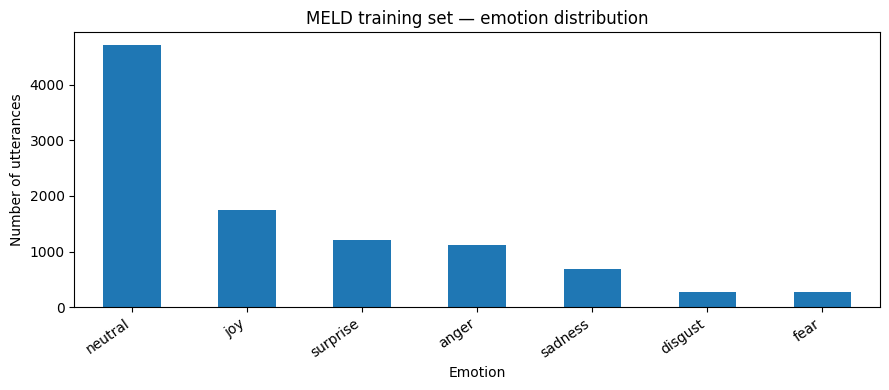

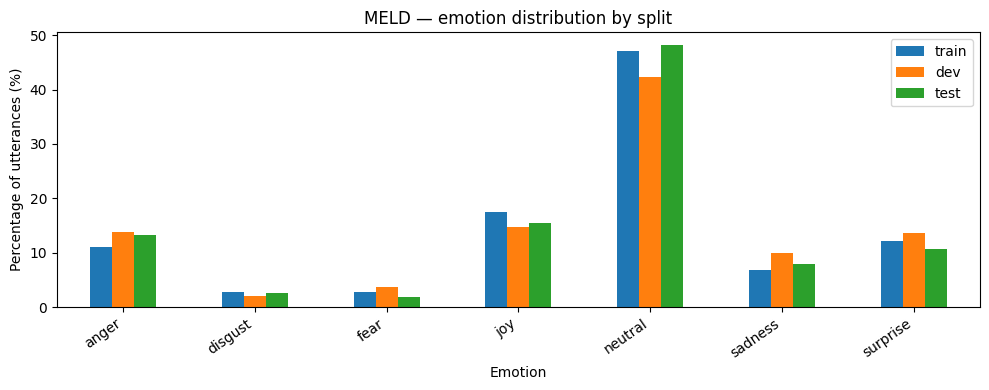

In [18]:
# Chart 1: emotion distribution in training data
ax = emotion_table["train"].sort_values(ascending=False).plot(kind="bar", figsize=(9, 4))
ax.set_title("MELD training set — emotion distribution")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of utterances")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "train_emotion_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# Chart 2: relative emotion distribution by split
ax = emotion_pct.plot(kind="bar", figsize=(10, 4))
ax.set_title("MELD — emotion distribution by split")
ax.set_xlabel("Emotion")
ax.set_ylabel("Percentage of utterances (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "emotion_distribution_by_split.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Sentiment distribution

`Sentiment` is a **different** target from `Emotion`. For this dissertation, seven-class emotion recognition is the primary classification task.

,train,dev,test
Sentiment,,,
negative,2945,406,833
neutral,4710,470,1256
positive,2334,233,521


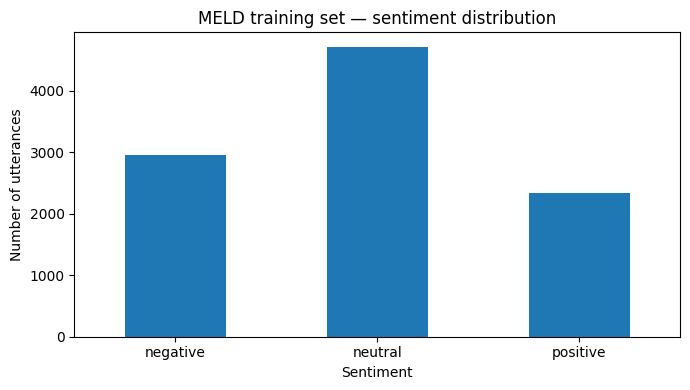

In [19]:
sentiment_labels = sorted(
    set().union(*(df["Sentiment"].dropna().astype(str).unique() for df in datasets.values()))
)

sentiment_table = pd.DataFrame({
    split: df["Sentiment"].value_counts().reindex(sentiment_labels, fill_value=0)
    for split, df in datasets.items()
})
sentiment_table.index.name = "Sentiment"
display(sentiment_table)
sentiment_table.to_csv(report_dir / "eda_sentiment_counts.csv")

ax = sentiment_table["train"].plot(kind="bar", figsize=(7, 4))
ax.set_title("MELD training set — sentiment distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of utterances")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_dir / "train_sentiment_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Explore speakers and dialogue structure

Speaker frequency matters because different people appear with different frequencies. We must not assume that every visible face is the labelled speaker.

Top 10 speakers in training data:


,Utterances
Speaker,
Joey,1510
Ross,1458
Rachel,1435
Phoebe,1321
Monica,1299
Chandler,1283
Janice,58
Carol,46
Emily,43


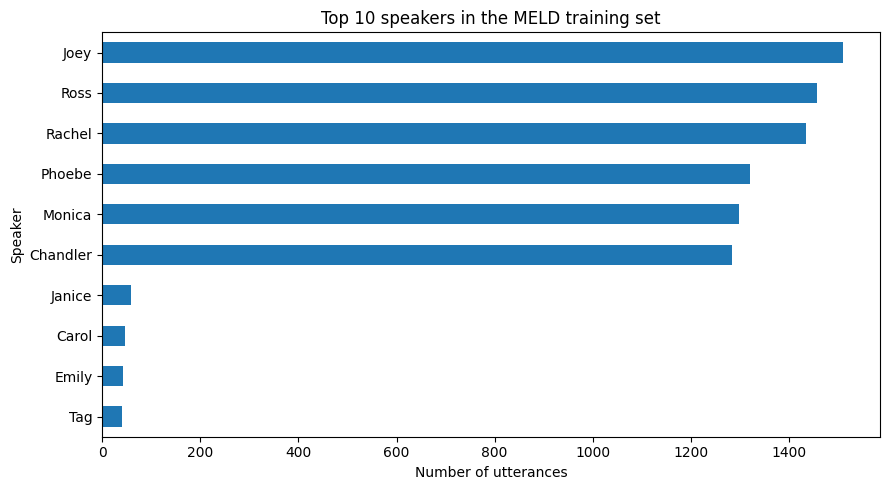


Dialogue statistics:


,Split,Dialogs,Mean utterances per dialogue,Median utterances per dialogue,Maximum utterances in a dialogue
0,train,1038,9.62,9.0,24
1,dev,114,9.73,10.0,23
2,test,280,9.32,9.0,33


In [20]:
print("Top 10 speakers in training data:")
top_speakers = train_df["Speaker"].value_counts().head(10)
display(top_speakers.rename("Utterances").to_frame())

ax = top_speakers.sort_values().plot(kind="barh", figsize=(9, 5))
ax.set_title("Top 10 speakers in the MELD training set")
ax.set_xlabel("Number of utterances")
ax.set_ylabel("Speaker")
plt.tight_layout()
plt.savefig(figures_dir / "top_training_speakers.png", dpi=160, bbox_inches="tight")
plt.show()

print("\nDialogue statistics:")
dialogue_stats = []
for split, df in datasets.items():
    lengths = df.groupby("Dialogue_ID").size()
    dialogue_stats.append({
        "Split": split,
        "Dialogs": len(lengths),
        "Mean utterances per dialogue": round(lengths.mean(), 2),
        "Median utterances per dialogue": float(lengths.median()),
        "Maximum utterances in a dialogue": int(lengths.max()),
    })
dialogue_stats_df = pd.DataFrame(dialogue_stats)
display(dialogue_stats_df)
dialogue_stats_df.to_csv(report_dir / "eda_dialogue_statistics.csv", index=False)

## 8. Explore utterance lengths

Word counts here describe **transcribed text**, not acoustic duration. True audio/video duration will be examined with the audiovisual files.


TRAIN utterance word count:


,Word count
count,9989.00
mean,7.95
std,6.23
min,1.00
25%,3.00
50%,6.00
75%,11.00
max,69.00



DEV utterance word count:


,Word count
count,1109.00
mean,7.92
std,5.98
min,1.00
25%,3.00
50%,6.00
75%,11.00
max,37.00



TEST utterance word count:


,Word count
count,2610.00
mean,8.22
std,6.36
min,1.00
25%,3.00
50%,7.00
75%,12.00
max,45.00


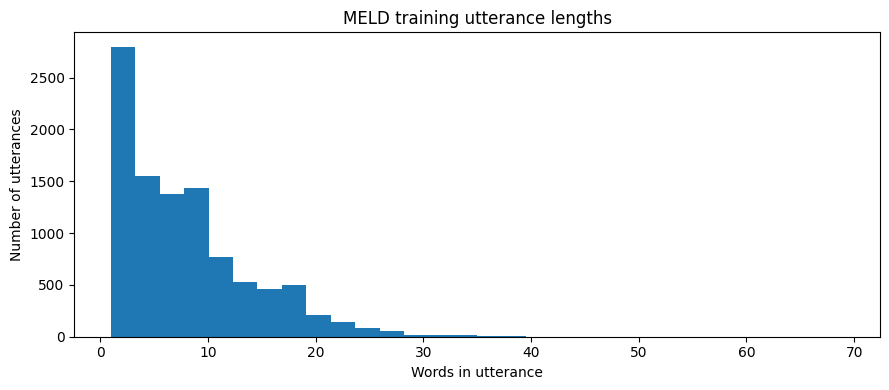

In [21]:
for split, df in datasets.items():
    lengths = df["Utterance"].fillna("").astype(str).str.split().str.len()
    print(f"\n{split.upper()} utterance word count:")
    display(lengths.describe().round(2).rename("Word count").to_frame())

train_word_counts = train_df["Utterance"].fillna("").astype(str).str.split().str.len()
plt.figure(figsize=(9, 4))
plt.hist(train_word_counts, bins=30)
plt.title("MELD training utterance lengths")
plt.xlabel("Words in utterance")
plt.ylabel("Number of utterances")
plt.tight_layout()
plt.savefig(figures_dir / "train_utterance_word_counts.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Basic audiovisual file overview

MELD clips contain video and typically an audio track. This section **counts MP4 files** and checks whether each annotation has a matching video path. It does not verify video readability or confirm an audio stream in every clip. The train/dev/test videos can be nested inside additional folders, so we use `rglob`.

In [22]:
video_lookup = {}
coverage_rows = []

for split, df in datasets.items():
    # Find MP4 files recursively, including nested folders such as train_splits.
    paths = sorted(
    p for p in (data_dir / split).rglob("*.mp4")
    if not p.name.startswith("._")
    )
    lookup = {p.stem: p for p in paths}
    video_lookup[split] = lookup

    expected_names = [
        f"dia{int(dialogue_id)}_utt{int(utterance_id)}"
        for dialogue_id, utterance_id in zip(df["Dialogue_ID"], df["Utterance_ID"])
        if pd.notna(dialogue_id) and pd.notna(utterance_id)
    ]
    found_count = sum(name in lookup for name in expected_names)
    coverage_rows.append({
        "Split": split,
        "Annotation rows": len(df),
        "MP4 files found": len(paths),
        "Annotations with matching MP4": found_count,
        "Annotations without matching MP4": len(expected_names) - found_count,
        "Rows with missing video IDs": len(df) - len(expected_names),
    })

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)
coverage_df.to_csv(report_dir / "eda_video_file_coverage.csv", index=False)

print("Note: This is a filename-matching overview; it does not prove that a clip plays correctly.")

,Split,Annotation rows,MP4 files found,Annotations with matching MP4,Annotations without matching MP4,Rows with missing video IDs
0,train,9989,9989,9989,0,0
1,dev,1109,1112,1108,1,0
2,test,2610,2747,2610,0,0


Note: This is a filename-matching overview; it does not prove that a clip plays correctly.


## 10. Inspect a few video properties (optional)

OpenCV can show a clip's FPS, frame count and resolution. This **does not assess facial quality**, nor does it inspect its audio track. The deeper video and facial EDA belongs in `02_facial_data_analysis.ipynb`; speech waveform and spectrogram EDA belongs in `03_speech_data_analysis.ipynb`.

In [23]:
try:
    import cv2
except ImportError:
    print("OpenCV is unavailable. Install it later to inspect video properties.")
else:
    sample_videos = list(video_lookup["train"].values())[:5]
    video_info = []
    for path in sample_videos:
        capture = cv2.VideoCapture(str(path))
        if not capture.isOpened():
            video_info.append({"File": path.name, "Readable": False})
            continue
        fps = capture.get(cv2.CAP_PROP_FPS)
        frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        capture.release()
        video_info.append({
            "File": path.name,
            "Readable": True,
            "FPS": round(fps, 2),
            "Frames": frames,
            "Duration (seconds)": round(frames / fps, 2) if fps > 0 else None,
            "Width": width,
            "Height": height,
        })
    display(pd.DataFrame(video_info))
    print("Preview only: up to five training videos were inspected.")

,File,Readable,FPS,Frames,Duration (seconds),Width,Height
0,dia0_utt0.mp4,True,23.98,136,5.67,1280,720
1,dia0_utt1.mp4,True,23.98,36,1.50,1280,720
2,dia0_utt10.mp4,True,23.98,48,2.00,1280,720
3,dia0_utt11.mp4,True,23.98,199,8.30,1280,720
4,dia0_utt12.mp4,True,23.98,74,3.09,1280,720


Preview only: up to five training videos were inspected.


## 11. Save a small EDA summary

These reports contain aggregated statistics and are safe to review before committing. No raw videos, cropped facial images or audio recordings are copied into `reports/`.

In [24]:
summary_rows = []
for split, df in datasets.items():
    summary_rows.append({
        "Split": split,
        "Utterances": len(df),
        "Columns": df.shape[1],
        "Missing cells": int(df.isna().sum().sum()),
        "Exact duplicate rows (check only)": int(df.duplicated().sum()),
        "Duplicate dialogue/utterance IDs (check only)": int(
            df.duplicated(subset=["Dialogue_ID", "Utterance_ID"]).sum()
        ),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(report_dir / "eda_summary.csv", index=False)
display(summary_df)

print("EDA finished. Small tables saved in:", report_dir)
print("Graphs saved in:", figures_dir)

,Split,Utterances,Columns,Missing cells,Exact duplicate rows (check only),Duplicate dialogue/utterance IDs (check only)
0,train,9989,11,0,0,0
1,dev,1109,11,0,0,0
2,test,2610,11,0,0,0


EDA finished. Small tables saved in: d:\Multimodal-Emotion-Recognition-Using-Facial-Expressions-and-Speech\reports
Graphs saved in: d:\Multimodal-Emotion-Recognition-Using-Facial-Expressions-and-Speech\reports\figures


## 12. Findings and next research stages

**Write your observations here after running all cells:**

- **Class imbalance:** Which emotion occurs most often, and which occurs least often?
- **Missing values:** Are any columns incomplete?
- **Speech and facial availability:** Do annotation rows have corresponding MP4 clips? (A matching filename does *not* guarantee a visible speaking face or valid audio.)
- **Temporal prediction:** How many dialogues exist, and why must we preserve utterance order?
- **Limitations:** MELD's emotion label refers to the *utterance*. It is not a frame-level facial expression annotation; the person onscreen may not be speaking.

### Coming next (separate stages)

1. **Dataset validation and cleaning:** Check corrupt MP4s, anomalous annotation IDs, genuine duplicates and invalid label values; *flag first, never delete raw data automatically*.
2. **Facial/video analysis:** Inspect resolution, face sizes, blur, detection failure, and active-speaker identity (RetinaFace locates faces; it does not know who is speaking).
3. **Speech/audio analysis:** Extract audio, inspect sample rates, durations, waveforms, mel-spectrograms and silence.
4. **Multimodal alignment:** Match utterance-level labels with the correct speaking-face sequence and audio, preserving split, dialogue ID, utterance ID and frame timestamps.

**GitHub note:** Your `/data/` directory is ignored, which is appropriate for the raw videos. Before committing the notebook, review or clear its saved cell outputs (especially any media) and commit just the notebook plus small aggregate reports/figures.

In [27]:

# Compare annotations for dia125_utt3
# across the training and test splits

for name, df in [
    ("Training", train_df),
    ("Testing", test_df)
]:
    record = df[
        (df["Dialogue_ID"] == 125) &
        (df["Utterance_ID"] == 3)
    ]

    print(f"\n===== {name} =====")

    if record.empty:
        print("No matching annotation found.")
    else:
        display(
            record[
                ["Dialogue_ID", "Utterance_ID",
                 "Speaker", "Utterance", "Emotion"]
            ]
        )



===== Training =====


,Dialogue_ID,Utterance_ID,Speaker,Utterance,Emotion
1165,125,3,Ross,"Oh, no-no-no, see, that-that clock’s a little fast, uh, we have 17 minutes.",neutral



===== Testing =====


,Dialogue_ID,Utterance_ID,Speaker,Utterance,Emotion
1143,125,3,Rachel,"Ohh, my new assistant is working out, yes.",neutral


In [28]:

# Compare video filenames with MELD annotations

from collections import Counter

for split, df in datasets.items():

    # Expected video names from CSV annotations
    expected = {
        f"dia{int(row.Dialogue_ID)}_utt{int(row.Utterance_ID)}"
        for row in df.itertuples()
    }

    # Find actual video files
    video_files = [
        file
        for file in (data_dir / split).rglob("*.mp4")
        if not file.name.startswith("._")
    ]

    video_counts = Counter(
        file.stem for file in video_files
    )

    actual = set(video_counts)

    missing = sorted(expected - actual)
    extra = sorted(actual - expected)
    duplicates = {
        name: count
        for name, count in video_counts.items()
        if count > 1
    }

    print(f"\n===== {split.upper()} =====")
    print("Annotations:", len(df))
    print("Video files:", len(video_files))
    print("Missing videos:", len(missing))
    print("Extra video names:", len(extra))
    print("Duplicate video names:", len(duplicates))

    print("Missing examples:", missing[:10])
    print("Extra examples:", extra[:10])
    print("Duplicate examples:", list(duplicates.items())[:10])



===== TRAIN =====
Annotations: 9989
Video files: 9989
Missing videos: 0
Extra video names: 0
Duplicate video names: 0
Missing examples: []
Extra examples: []
Duplicate examples: []

===== DEV =====
Annotations: 1109
Video files: 1112
Missing videos: 1
Extra video names: 4
Duplicate video names: 0
Missing examples: ['dia110_utt7']
Extra examples: ['dia49_utt4', 'dia49_utt5', 'dia66_utt10', 'dia66_utt9']
Duplicate examples: []

===== TEST =====
Annotations: 2610
Video files: 2747
Missing videos: 0
Extra video names: 137
Duplicate video names: 0
Missing examples: []
Extra examples: ['dia108_utt1', 'dia108_utt2', 'dia93_utt5', 'dia93_utt6', 'dia93_utt7', 'final_videos_testdia100_utt1', 'final_videos_testdia100_utt10', 'final_videos_testdia100_utt11', 'final_videos_testdia100_utt16', 'final_videos_testdia100_utt17']
Duplicate examples: []
